## Zadání

Máme mikrofonové pole (soustavu mikrofonů) se známými souřadnicemi jednotlivých mikrofonů.
V prostoru se pohybuje jediný zdroj zvuku, jehož signál je zaznamenán všemi mikrofony - vznikne tedy vícekanálový záznam.

Úkolem je odhadnout trajektorii pohybu zdroje zvuku na základě tohoto vícekanálového záznamu.

Kód, který generuje vícekanálový záznam, a ve kterém jsou zaznamenány souřadnice mikrofonů, je uveden v části Vypracování.
Přiloženy jsou i další funkce, které ovšem nemusíte používat - vytvoření vlastních (ideálně lepších) variant těchto funkcí bude chápáno jako vypracování nad rámec zadání.

## Vypracování

Budeme potřebovat tyto knihovny:

In [1]:
import numpy as np
from scipy.optimize import least_squares

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

### Definování konstant

Definujeme si duležité konstanty:
*   délku trvání nahrávky,
*   vzorkovací frekvenci nahrávky,
*   počet vzorků nahrávky,
*   rychlost zvuku v normálním prostředí.

In [2]:
T = 10  # Total duration [s]
sample_rate = 8000  # Samples per second [Hz]
n_samples = int(T * sample_rate)  # Total number of samples
v_normal = 340  # Speed of sound [m/s]

### Uspořádání mikrofonového pole

Vytvoříme matici, kde první index je pořadí mikrofonu v poli a druhý index souřadnice příslušného mikrofonu.

Mikrofony jsou v umístěny v rozích krychle o straně 1 metr.

Pozice mikrofonů je zakreslena v 3D grafu.

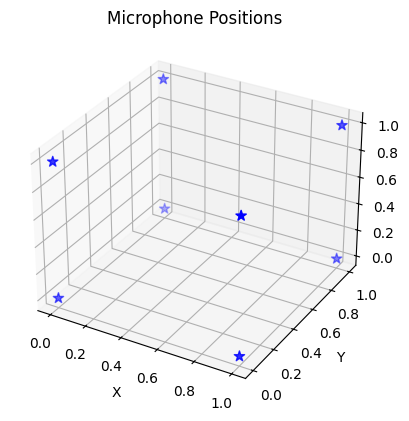

In [3]:
# Define the 3D positions of microphones in the array
# Shape: (n_mics, 3) → each row corresponds to [x, y, z] coordinates of a microphone
# This example arranges 8 microphones at the corners of a unit cube.
mic_field_coordinates = np.array([
    [0, 0, 0],  # Bottom-front-left
    [0, 0, 1],  # Bottom-front-right
    [0, 1, 0],  # Bottom-back-left
    [0, 1, 1],  # Bottom-back-right
    [1, 0, 0],  # Top-front-left
    [1, 0, 1],  # Top-front-right
    [1, 1, 0],  # Top-back-left
    [1, 1, 1],  # Top-back-right
])

def plot_mic_field_coordinates(mic_field_coordinates, title):
    """
    Visualize the 3D spatial layout of microphones.

    Args:
        mic_field_coordinates (np.ndarray): Array of shape (n_mics, 3),
            where each row is [x, y, z] coordinates of a microphone.
        title (str): Plot title for visualization.
    """
    # Create a 3D plot
    ax = plt.figure().add_subplot(111, projection='3d')

    # Plot microphone positions as blue stars
    ax.scatter(
        mic_field_coordinates[:, 0],  # X-coordinates
        mic_field_coordinates[:, 1],  # Y-coordinates
        mic_field_coordinates[:, 2],  # Z-coordinates
        c='blue', marker='*', s=60
    )

    # Label axes and set title
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_title(title)

    plt.show()

# Plot the microphone array in 3D
plot_mic_field_coordinates(mic_field_coordinates, title="Microphone Positions")

### Generování skutečné trajektorie zdroje signálu

V poli necháme pochybovat se zdroj signálu po šroubovici nahoru. Uděláme dva závity šroubovice.

In [4]:
# Time vector spanning [0, T) with a step of 1/sample_rate
t = np.arange(0, n_samples) / sample_rate  # Shape: (n_samples,)

# Generate ground-truth 3D trajectory
# Shape: (n_samples, 3) → each row = [x, y, z] position at time t[i]
#
# Description:
# - X and Y follow a circular (sin/cos) path → horizontal rotation
# - Z increases linearly with time → forming a smooth upward helix

positions_gt_x = 0.5 + 0.5 * np.sin(t * 4 * np.pi / T)  # horizontal circular motion (sin)
positions_gt_y = 0.5 + 0.5 * np.cos(t * 4 * np.pi / T)  # horizontal circular motion (cos)
positions_gt_z = t / T                                  # normalized height (0 → 1 over 10 s)

# Stack coordinates into a single array
positions_gt = np.column_stack((positions_gt_x, positions_gt_y, positions_gt_z))

# positions_gt now contains a helical trajectory sampled at 8 kHz for 10 seconds

Vytvoříme funkci na vykreslení trajektorie a pozice mikrofonů.

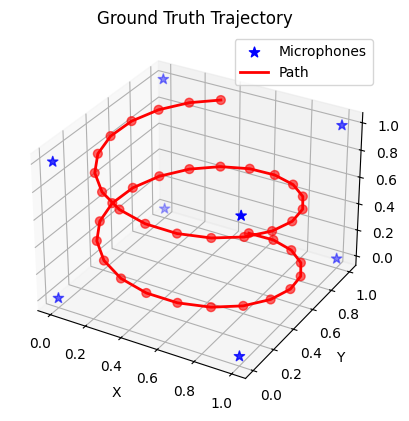

In [5]:
def plot_positions(mic_field_coordinates, positions, title):
    """
    Visualize 3D microphone positions and source trajectory.

    Args:
        mic_field_coordinates (np.ndarray): Array of shape (n_mics, 3)
            containing [x, y, z] coordinates of microphones.
        positions (np.ndarray): Array of shape (n_positions, 3)
            containing the [x, y, z] coordinates of the sound source
            over time (e.g., a trajectory).
        title (str): Title for the 3D plot.
    """
    # Create a 3D figure and axis
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')

    # --- Plot microphones ---
    ax.scatter(
        mic_field_coordinates[:, 0],
        mic_field_coordinates[:, 1],
        mic_field_coordinates[:, 2],
        c='blue', marker='*', s=60, label="Microphones"
    )

    # Plot source trajectory
    # Line for continuous movement + scatter points for sampled positions
    ax.plot(
        positions[:, 0],
        positions[:, 1],
        positions[:, 2],
        c='red', linewidth=2, linestyle='-',
        label='Path'
    )
    ax.scatter(
        positions[:, 0],
        positions[:, 1],
        positions[:, 2],
        c='red', marker='o', s=40, alpha=0.6
    )

    # Axis labels and legend
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_title(title)
    ax.legend()

    plt.show()

# Plot only every 2000th sample to reduce visual clutter
plot_positions(mic_field_coordinates, positions_gt[::2000, :], title="Ground Truth Trajectory")

### Generování vícekanálového zvuku

Zdroj zvuku se pohybuje. Každý mikrofon zaznamenává zvuk zpožděný úměrně k vzdálensoti od zdroje zvuku a rychlosti zvuku. Zvuk je navíc utlumený proporcionálně k vzdálenosti od zdroje zvuku. Každý mikrofon přidává do zvuku náhodný šum. Navíc, použitá rychlost zvuku je jiná než je rychlost pro normální prostředí a není známá.

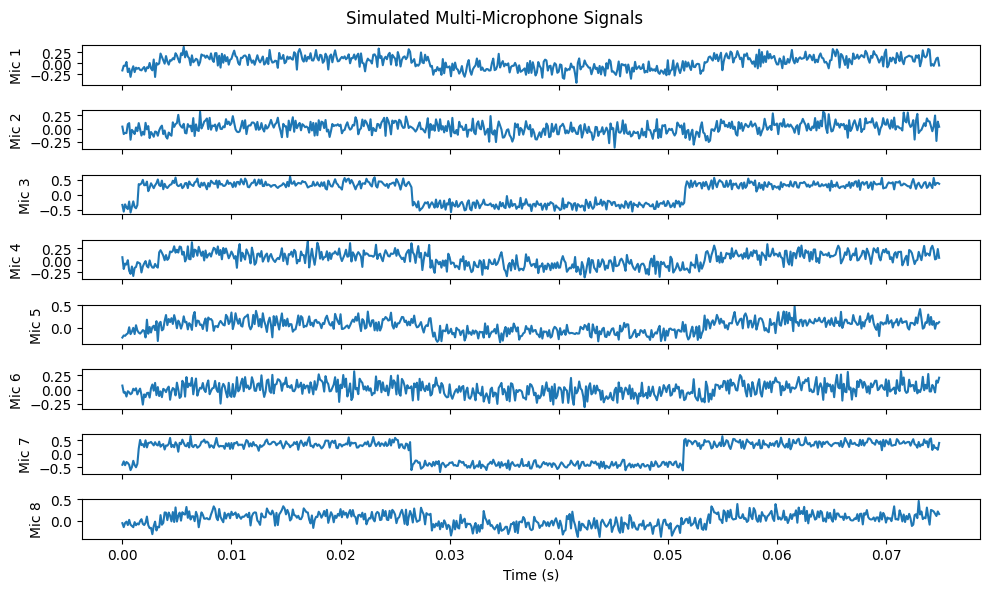

In [6]:
np.random.seed(42)

def gen_one_channel(source_positions, mic_position, n_samples, t, v):
    """
    Generate a single-channel audio signal received by one microphone
    from a moving sound source.

    Args:
        source_positions (np.ndarray): Array of shape (n_samples, 3),
            giving the 3D source position [x, y, z] at each time step.
        mic_position (np.ndarray): Array of shape (3,), giving the
            microphone position [x, y, z].
        n_samples (int): Number of samples (time steps).
        t (np.ndarray): Time vector of shape (n_samples,).
        v (float): Speed of sound [m/s].

    Returns:
        np.ndarray: Simulated audio signal for one microphone, shape (n_samples,).
    """
    f = 20  # Source frequency [Hz]

    # Distance from source to microphone at each time step
    mic_position_expanded = np.expand_dims(mic_position, axis=0)
    d = np.linalg.norm(source_positions - mic_position_expanded, axis=-1)  # (n_samples,)

    # Propagation delay (distance / speed of sound)
    delay = d / v
    t_shifted = t - delay  # Time delayed signal

    # Amplitude attenuation due to distance (inverse exponential)
    amplitude = np.exp(-2.0 * d)

    # Generate sine wave with propagation delay
    sound = np.sin(2 * np.pi * f * t_shifted)

    # Optional: convert to square wave (sign)
    sound = np.sign(sound)

    # Apply amplitude attenuation
    sound *= amplitude

    return sound  # Shape: (n_samples,)


def gen_multichannel_signal(source_positions, mic_positions, n_samples, t, v):
    """
    Generate multi-channel signals for all microphones.

    Args:
        source_positions (np.ndarray): (n_samples, 3) source trajectory.
        mic_positions (np.ndarray): (n_mics, 3) microphone coordinates.
        n_samples (int): Number of samples.
        t (np.ndarray): Time vector.
        v (float): Speed of sound [m/s].

    Returns:
        np.ndarray: Simulated multi-mic signal array, shape (n_mics, n_samples).
    """
    return np.array([
        gen_one_channel(source_positions, mic_positions[i_mic], n_samples, t, v)
        for i_mic in range(mic_positions.shape[0])
    ])


v = v_normal + np.random.randint(-10, +10)  # Slight variation per simulation

signal = gen_multichannel_signal(
    source_positions=positions_gt,
    mic_positions=mic_field_coordinates,
    n_samples=n_samples,
    t=t,
    v=v
)

# You are not alowed to know value of v.
# ... Well, you can print it above but don't do it.
v = None

# Add Gaussian noise
signal += np.random.normal(0, 0.1, signal.shape)

# Plot first 600 samples for each channel
fig, axs = plt.subplots(signal.shape[0], 1, figsize=(10, 6), sharex=True)
for i_channel in range(signal.shape[0]):
    axs[i_channel].plot(t[:600], signal[i_channel, :600])
    axs[i_channel].set_ylabel(f'Mic {i_channel + 1}')
axs[-1].set_xlabel('Time (s)')
fig.suptitle("Simulated Multi-Microphone Signals")
plt.tight_layout()
plt.show()


### Segmentace signálu

Rozdělíme signál na okénka dané délky. Okénka budeme po signálu posunovat s daným posunem.

**Úprava!**

Segmentace signálu na okna o délce 0.1s = 100ms, tudíž každé okno (segment) obsahuje 800 vzorků (samples).

Overlap (překryv/posun) = 0.05s = 50ms, tudíž celkem 199 oken => vzniká struktura (pole) `segments`, kde index_segmentu(0-198), index_mikrofonu(0-7), index_vzorku(0-799)

In [7]:
# Délka a velikost segmentu (100ms = 800vzorků)
window_duration = 0.1
window_size = int(window_duration * sample_rate)

# Posun (50ms = 400 vzorků)
overlap_duration = 0.05
overlap_size = int(overlap_duration * sample_rate)

# Počet segmentů
n_segments = int(np.floor((n_samples - window_size) / overlap_size)) + 1

# Segmentování signálu
segments = []
for i in range(n_segments):
    start_sample = i * overlap_size
    end_sample = start_sample + window_size
    segments.append(signal[:, start_sample:end_sample])

segments = np.array(segments)

print(f"Počet segmentů = {n_segments} segmentů.")
print(f"Překryv ve vzorkách = {overlap_size}")
print(f"Počet vzorků v segmentu = {window_size} vzorků.")
print(f"Tvar (shape) segmentů: {segments.shape}")

Počet segmentů = 199 segmentů.
Překryv ve vzorkách = 400
Počet vzorků v segmentu = 800 vzorků.
Tvar (shape) segmentů: (199, 8, 800)


**Úprava!**

vykreslení průběhu signálu 1. segmentu pro všechny mikrofony (0-100 ms, 800 vzorků)

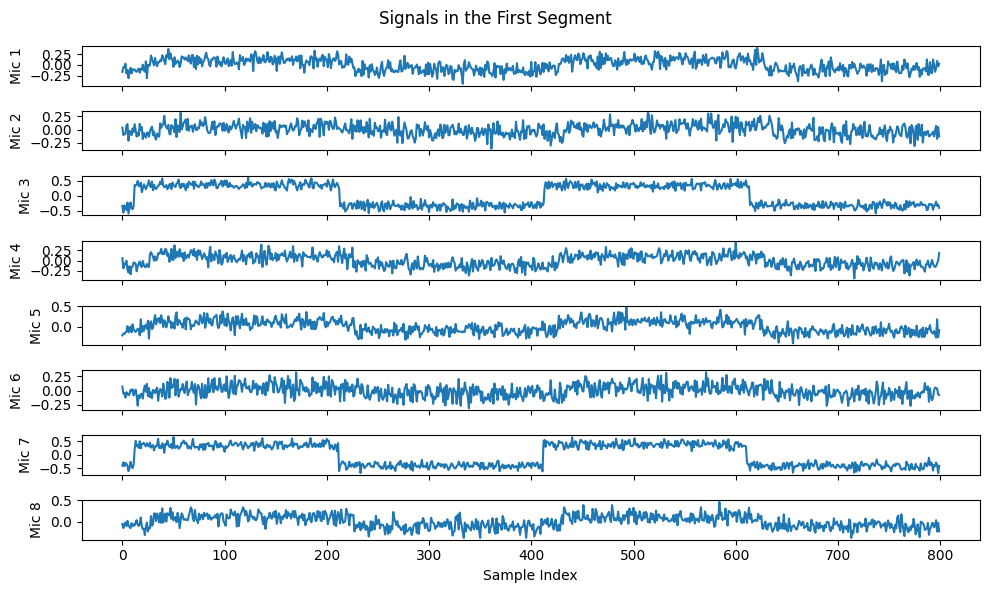

In [8]:
# Vykreslení 1. segmentu signálu
fig, axs = plt.subplots(segments.shape[1], 1, figsize=(10, 6), sharex=True)
for i_channel in range(segments.shape[1]):
    axs[i_channel].plot(segments[0, i_channel, :])
    axs[i_channel].set_ylabel(f'Mic {i_channel + 1}')
axs[-1].set_xlabel('Sample Index')
fig.suptitle("Signals in the First Segment")
plt.tight_layout()
plt.show()

**Úprava!**

### Vylepšení zpracování signálu: Dolnopropustná filtrace

Pro zlepšení odhadu časového zpoždění a následné trajektorie zdroje zvuku aplikuji na vícekanálový signál dolnopropustný filtr. Cílem je odstranit velké množství (vysokofrekvenčního) šumu, který může znehodnocovat odhady křížové korelace.

In [9]:
from scipy import signal

def lowpass_filter(data, cutoff, sample_rate, order=5):
    nyquist = 0.5 * sample_rate
    normal_cutoff = cutoff / nyquist
    # Získání koeficientů filtru
    b, a = signal.butter(order, normal_cutoff, btype='low', analog=False)
    # Aplikace filtru (filtfilt pro nulové fázové zkreslení)
    y = signal.filtfilt(b, a, data)
    return y

### Aplikace dolnopropustného filtru na segmenty

Aplikování definovaného `lowpass_filter` na každý segment, který byl vytvořen. Získání `filtered_segments`, se kterými se bude dále pracovat pro výpočet rozdílů vzdáleností.

Segmenty filtrovány s mezní frekvencí 750 Hz a řádem 7.
Tvar filtrovaných segmentů: (199, 8, 800)


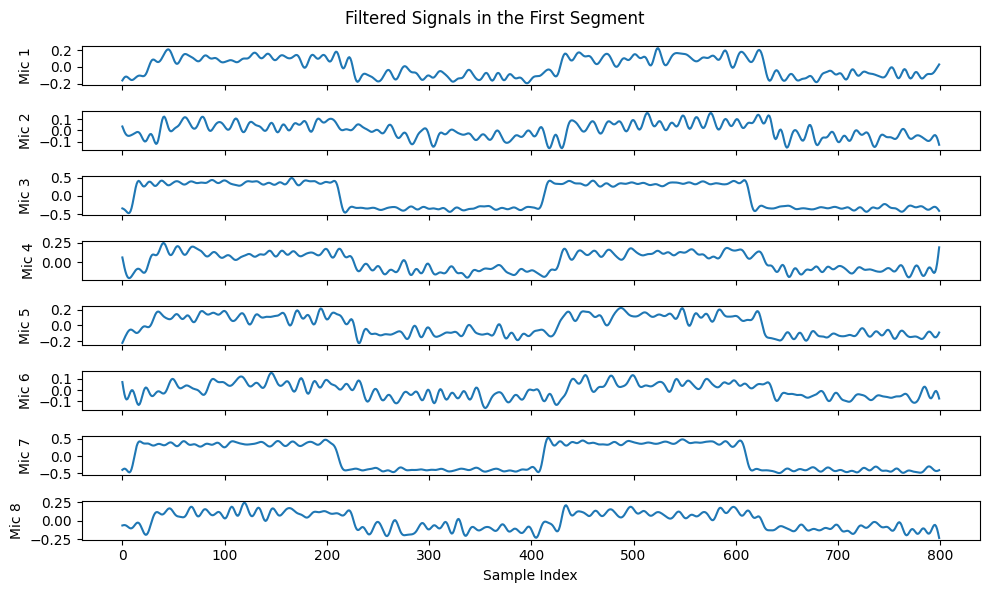

In [10]:
# Aplikujeme filtr na každý segment a každý kanál zvlášť
# Ladění parametrů dle experimentu -> výsledné (patrně) nejlepší:
cutoff_freq = 750 # Hz
filter_order = 7  # Řád filtru

filtered_segments = np.zeros_like(segments)

for i_segment in range(n_segments):
    for i_channel in range(segments.shape[1]):
        filtered_segments[i_segment, i_channel, :] = lowpass_filter(
            segments[i_segment, i_channel, :],
            cutoff_freq,
            sample_rate,
            order=filter_order
        )

print(f"Segmenty filtrovány s mezní frekvencí {cutoff_freq} Hz a řádem {filter_order}.")
print(f"Tvar filtrovaných segmentů: {filtered_segments.shape}")

# Vykreslení 1. segmentu filtorvaného signálu
fig, axs = plt.subplots(filtered_segments.shape[1], 1, figsize=(10, 6), sharex=True)
for i_channel in range(filtered_segments.shape[1]):
    axs[i_channel].plot(filtered_segments[0, i_channel, :])
    axs[i_channel].set_ylabel(f'Mic {i_channel + 1}')
axs[-1].set_xlabel('Sample Index')
fig.suptitle("Filtered Signals in the First Segment")
plt.tight_layout()
plt.show()

### Výpočet matic rozdílů vzdáleností

V souladu s přednáškami, vytvořímě funkci na odhad časového zpoždění dvou signálů. Navíc přidáme omezení odhadu časového posunu pro mikrofony se známou polohou. Je přidán i mechanismus, který dovoluje odhadnout záporný časový posun.

In [11]:
def compute_max_delay(mic_position_a, mic_position_b, v, sample_rate):
    """
    Compute the maximum possible time delay (in samples)
    between two microphones based on their distance.

    Args:
        mic_position_a (np.ndarray): (3,) coordinates of microphone A.
        mic_position_b (np.ndarray): (3,) coordinates of microphone B.
        v (float): Speed of sound [m/s].
        sample_rate (float): Sampling rate [Hz].

    Returns:
        int: Maximum possible delay in samples.
    """
    # Vypočítá euklidovskou vzdálenost mezi dvěma mikrofony v metrech
    d = np.linalg.norm(mic_position_a - mic_position_b)
    # Vypočítá maximální možné zpoždění v sekundách a převede ho na vzorky
    delay_max = int(np.ceil(d / v * sample_rate))
    return delay_max


def compute_delay_simple(x_a, x_b, max_delay):
    """
    Estimate the time delay between two signals using FFT-based cross-correlation.

    Args:
        x_a (np.ndarray): Signal from microphone A (1D array).
        x_b (np.ndarray): Signal from microphone B (1D array).
        max_delay (int): Maximum delay to consider (in samples).

    Returns:
        int: Estimated delay (in samples). Positive means A lags B.
    """
    # Vypočítá křížové korelace mezi signály x_a a x_b pomocí FFT (spectrum)
    X_a = np.fft.fft(x_a)
    X_b = np.fft.fft(x_b)
    X_ab = X_a * np.conj(X_b)

    # Zpětná FFT pro získání křížové korelace v časové doméně
    x_ab = np.fft.ifft(X_ab).real

    # Vezme pouze relevantní část korelační funkce do maximálního zpoždění
    corr_segment = x_ab[:max_delay]

    # Zpoždění odpovídá indexu s maximální korelací
    delay_samples = np.argmax(corr_segment)
    return delay_samples


def compute_delay_complex(mic_posiion_a, mic_position_b, signal_a, signal_b, sample_rate, v):
    """
    Estimate relative delay (in seconds) between two microphone signals based on their positions.

    Args:
        mic_position_a: np.ndarray, position of microphone A (x, y, z)
        mic_position_b: np.ndarray, position of microphone B (x, y, z)
        signal_a: np.ndarray, waveform from microphone A
        signal_b: np.ndarray, waveform from microphone B
        sample_rate: int, sampling rate in Hz
        v: float, speed of sound (m/s)

    Returns:
        float: estimated delay in seconds (positive if signal_a lags signal_b)
    """

    # Vypočítá maximální možné zpoždění v rámci daných pozic mikrofonů a rychlosti zvuku
    # Používá mírně sníženou rychlost zvuku (v-20) pro bezpečný rozsah
    max_delay = compute_max_delay(mic_posiion_a, mic_position_b, v - 20, sample_rate)

    # Odhadne relativní zpoždění v rámci maximálního zpoždění
    # delay_a: zpoždění B vůči A
    # delay_b: zpoždění A vůči B
    delay_a = compute_delay_simple(signal_b, signal_a, max_delay)
    delay_b = compute_delay_simple(signal_a, signal_b, max_delay)
    # Výsledné zpoždění je rozdíl těchto dvou hodnot
    delay_samples = delay_a - delay_b

    # Převede zpoždění ze vzorků na sekundy
    delay_seconds = delay_samples / sample_rate

    return delay_seconds

**Úprava!**

- doplněn výpočet matic rozdílů vzdáleností
- vzniká struktura `deltas_L_estimated` -> (index 1. mikrofonu(0-7), index 2. mikrofonu(0-7), segment(0-198)) a představuje odhadnutý rozdíl vzdáleností mezi zdrojem zvuku a mikrofonem s indexem i a zdrojem zvuku a mikrofonem s indexem j pro daný časový segment => Tento rozdíl vzdáleností byl odhadnut na základě: odhadu časového zpoždění mezi signály z mikrofonu i a mikrofonu j (`compute_delay_complex`) v tomto segmentu pomocí křížové korelace, a poté vynásobení tohoto odhadnutého časového zpoždění odhadovanou rychlostí zvuku (v_normal)

In [12]:
# Inicializace pole deltas_L_estimated
deltas_L_estimated = np.zeros((mic_field_coordinates.shape[0], mic_field_coordinates.shape[0], n_segments))

# Předpoklad, že rychlost vuku v = v_normal
estimated_v = v_normal

# Výpočet deltas_L_estimated s filtrovanými segmenty
for i_segment in range(n_segments):
    current_segment = filtered_segments[i_segment, :, :]

    # Iterace přes každý pár mikrofonů
    for i_mic_a in range(mic_field_coordinates.shape[0]):
        for i_mic_b in range(mic_field_coordinates.shape[0]):

            if i_mic_a == i_mic_b:
                deltas_L_estimated[i_mic_a, i_mic_b, i_segment] = 0
                continue

            signal_a = current_segment[i_mic_a, :]
            signal_b = current_segment[i_mic_b, :]

            mic_pos_a = mic_field_coordinates[i_mic_a, :]
            mic_pos_b = mic_field_coordinates[i_mic_b, :]

            estimated_delay_seconds = compute_delay_complex(
                mic_pos_a, mic_pos_b, signal_a, signal_b, sample_rate, estimated_v
            )

            deltas_L_estimated[i_mic_a, i_mic_b, i_segment] = estimated_delay_seconds * estimated_v

print(f"Shape of estimated distance differences: {deltas_L_estimated.shape}")

# Výpis matice rozdílů vzdáleností pro 1. segment
print("First estimated distance difference matrix for segment 1:")
print(deltas_L_estimated[:, :, 0])

Shape of estimated distance differences: (8, 8, 199)
First estimated distance difference matrix for segment 1:
[[ 0.      0.4675 -0.595   0.0425 -0.0425  0.255  -0.68    0.1275]
 [-0.4675  0.     -1.0625 -0.51   -0.425  -0.1275 -1.0625 -0.3825]
 [ 0.595   1.0625  0.      0.6375  0.595   0.935  -0.0425  0.6375]
 [-0.0425  0.51   -0.6375  0.     -0.085   0.34   -0.68    0.0425]
 [ 0.0425  0.425  -0.595   0.085   0.      0.34   -0.6375  0.085 ]
 [-0.255   0.1275 -0.935  -0.34   -0.34    0.     -1.02   -0.2975]
 [ 0.68    1.0625  0.0425  0.68    0.6375  1.02    0.      0.7225]
 [-0.1275  0.3825 -0.6375 -0.0425 -0.085   0.2975 -0.7225  0.    ]]


### Odhad 3D souřadnic z matic rozdílů vzdáleností

Vytvoříme funkci, která z matice rozdílů vzdáleností mezi zdrojem zvuku a dvěma mikrofony pro každý segment vypočte odhad 3D souřadnic trajektorie zdroje zvuku.

Vstupní pole s polohami mikrofonů má v tomto pořadí tyto indexy:
1.  pořadí mikrofonu,
2.  pořadí souřadnice.

Vstupní matice rozdílů vzdáleností má v tomto pořadí tyto indexy:
1.  pořadí prvního mikrofonu,
2.  pořadí druhého mikrofonu,
3.  pořadí segmentu.

In [13]:
def compute_deltasL(mic_fied_coordinates, positions):
  """
    Compute predicted path length differences (ΔL) between all microphone pairs
    for a given set of source positions.

    Args:
        mic_field_coordinates (np.ndarray): (M, dim)
            Microphone coordinates. M = number of microphones.
        positions (np.ndarray): (T, dim)
            Source positions at each time step (T = number of time samples).

    Returns:
        np.ndarray: Predicted path length differences between microphones,
                    shape (M, M, T), where:
                        ΔL[i, j, t] = L_i(t) - L_j(t)
                        L_i(t) = distance from source to mic i at time t
  """

  # Expand arrays to enable broadcasting:
  # mic_field_coordinates_expanded: (M, 1, dim)
  # positions_expanded: (1, T, dim)
  mic_fied_coordinates_expanded = np.expand_dims(mic_fied_coordinates, axis=1)
  positions_expanded = np.expand_dims(positions, axis=0)

  # Compute distances from each mic to the source for each time step
  # Shape: (M, T)
  L2 = ((mic_fied_coordinates_expanded - positions_expanded) ** 2).sum(axis=-1)
  L = np.sqrt(L2)

  # Compute all pairwise distance differences between microphones
  # Shape: (M, M, T)
  deltasL = np.expand_dims(L, axis=0) - np.expand_dims(L, axis=1)

  return deltasL


def estimate_positions(mic_field_coordinates, deltasL):
    """
    Estimate source positions over time by minimizing the difference
    between measured and predicted inter-microphone distance differences (ΔL).

    Args:
        mic_field_coordinates (np.ndarray): (M, dim)
            Microphone coordinates. M = number of microphones, dim = 2 or 3.
        deltasL (np.ndarray): (M, M, T)
            Measured path length differences between microphone pairs
            for each time step.
        Returns:
            np.ndarray: Estimated source positions of shape (T, dim).
    """

    M, dim = mic_field_coordinates.shape
    _, _, T = deltasL.shape

    # Objective function — computes residuals between measured and predicted ΔL
    def residual(x_flat):
        """
        x_flat: flattened vector of all estimated source positions
                of shape (T * dim,)
        """
        x = x_flat.reshape((T, dim))  # reshape to (T, dim)

        # Compute predicted distance differences between mics
        deltasL_pred = compute_deltasL(mic_field_coordinates, x)

        # Flatten all residuals into a single 1D vector for least_squares()
        return (deltasL_pred - deltasL).ravel()

    # --- Initial guess for optimization ---
    # Start near the center of the microphone array
    centroid = mic_field_coordinates.mean(axis=0)
    positions_init = np.tile(centroid, (T,))  # flatten to (T * dim,)

    # --- Solve least-squares minimization problem ---
    result = least_squares(residual, positions_init, verbose=1)

    # --- Reshape optimized vector back into (T, dim) ---
    positions = result.x.reshape((T, dim))

    return positions

**Úprava!**

- Odhad 3D souřadnic trajektorie zdroje zvuku
- Využití matice rozdílů vzdáleností `deltas_L_estimated` a zadané funkce `estimate_positions`

In [14]:
# Odhad 3D souřadnic trajektorie zvuku
estimated_positions = estimate_positions(mic_field_coordinates, deltas_L_estimated)

print(f"Shape of estimated positions: {estimated_positions.shape}")


`ftol` termination condition is satisfied.
Function evaluations 6, initial cost 1.2903e+03, final cost 2.8863e+01, first-order optimality 4.39e-05.
Shape of estimated positions: (199, 3)


**Úprava!**

- Vizualizace odhadnuté (estimated) a "ground-truth" trajektorie dle zadané funkce plot_positions()


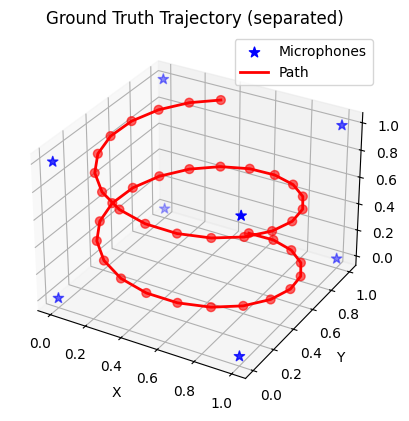

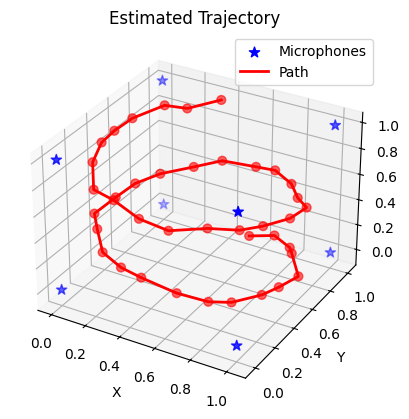

In [15]:
# Vizualizace přes plot_positions() - 1.ground-truth, 2.estimated
# Ground Truth Trajectory -> každý 2000. vzorek
plot_positions(mic_field_coordinates, positions_gt[::2000][:n_segments, :], title="Ground Truth Trajectory (separated)")
# Estimated Trajectory -> každý 5. vzorek
plot_positions(mic_field_coordinates, estimated_positions[::5], title="Estimated Trajectory")


## Vypracování nad rámec zadání

**Úprava!**

- Lepší vizualizace -> obě trajektorie (estimated i ground-truth) v jednom grafu

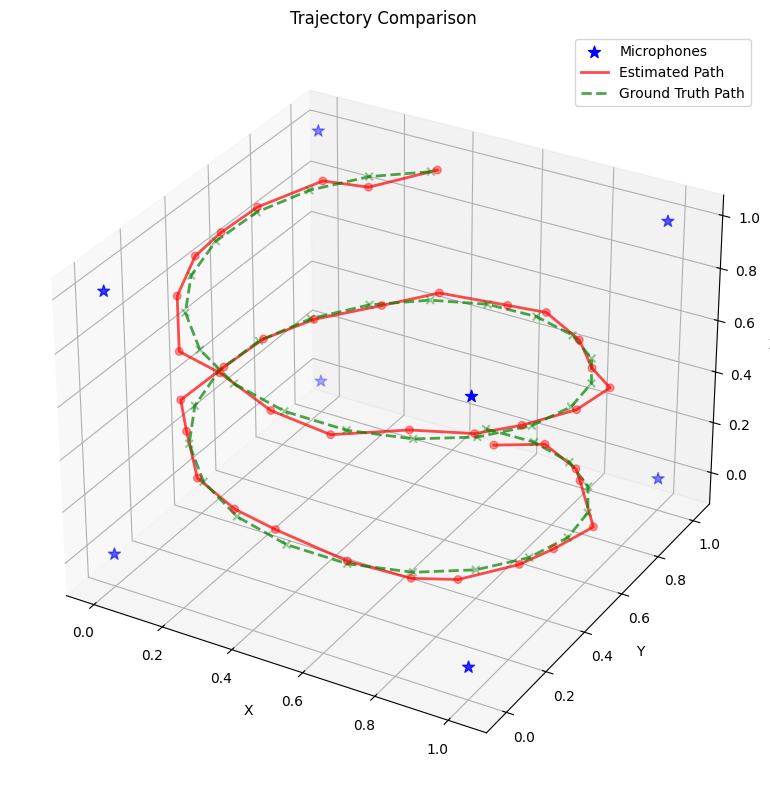

In [16]:
# Definování funkce k vykreslení
def plot_comparison_positions(mic_field_coordinates, estimated_positions, gt_positions, title="Trajectory Comparison"):
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')

    # Vykreslení mikrofonů
    ax.scatter(
        mic_field_coordinates[:, 0],
        mic_field_coordinates[:, 1],
        mic_field_coordinates[:, 2],
        c='blue', marker='*', s=80, label="Microphones"
    )

    # Vykreslení estimated trajektorie
    ax.plot(
        estimated_positions[::5, 0],
        estimated_positions[::5, 1],
        estimated_positions[::5, 2],
        c='red', linewidth=2, linestyle='-', alpha=0.7,
        label='Estimated Path'
    )
    ax.scatter(
        estimated_positions[::5, 0],
        estimated_positions[::5, 1],
        estimated_positions[::5, 2],
        c='red', marker='o', s=30, alpha=0.4
    )

    # Vykreslení ground-truth trajektorie
    ax.plot(
        gt_positions[::5, 0],
        gt_positions[::5, 1],
        gt_positions[::5, 2],
        c='green', linewidth=2, linestyle='--', alpha=0.7,
        label='Ground Truth Path'
    )
    ax.scatter(
        gt_positions[::5, 0],
        gt_positions[::5, 1],
        gt_positions[::5, 2],
        c='green', marker='x', s=30, alpha=0.4
    )

    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_title(title)
    ax.legend()
    ax.grid(True)

    plt.tight_layout()
    plt.show()

# Aplikování funkce k vykreslení
plot_comparison_positions(
    mic_field_coordinates,
    estimated_positions,
    positions_gt[::overlap_size][:n_segments, :],
)


## Závěr

V rámci této semestrální práce jsme se zabývali odhadem trajektorie pohybu zdroje zvuku na základě vícekanálového záznamu z mikrofonového pole. Provedli jsme následující kroky:

1.  **Segmentace signálu:** Vícekanálový zvukový signál byl rozdělen na kratší časové segmenty (100 [ms]) s definovaným překryvem (50 [ms]).
2.  **Vyhlazení segmentů:** Na jednotlivé segmenty jsme využili dolnopropustnou filtraci pomocí funkce `lowpass_filter`, abychom získali přesnější a kvalitnější odhad trajektorie
3.  **Výpočet matic rozdílů vzdáleností:** Pro každý filtorvaný segment a každou dvojici mikrofonů byl odhadnut časový posun mezi signály pomocí křížové korelace. Na základě těchto časových posunů a odhadované rychlosti zvuku byla vypočtena matice rozdílů vzdáleností.
4.  **Odhad 3D souřadnic trajektorie:** Využitím matic rozdílů vzdáleností a metody nejmenších čtverců byla pro každý časový segment odhadnuta 3D pozice zdroje zvuku, čímž byla získána odhadnutá trajektorie.
5.  **Vizualizace:** Skutečná a odhadnutá trajektorie byly vykresleny v 3D grafu pro vizuální porovnání.

Odhadnutá trajektorie ukazuje, že metoda dokáže zachytit celkový tvar pohybu zdroje zvuku, i přes přítomnost šumu v signálu a neznámou přesnou rychlost zvuku. Přesnost odhadu je ovlivněna kvalitou signálu, přesností odhadu časových zpoždění a použitým odhadem rychlosti zvuku.

Jako vypracování nad rámec zadání považuji:
- filtraci jednotlivých segmentů vícekanálového signálu pro lepší odhad
- kvalitní vizualizaci obou trajektorií